<a href="https://colab.research.google.com/github/tomvangasse/ATLAS-top-tagging-ML-project/blob/main/notebooks/03_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MLP

A Multi-Layer Perceptron (MLP) is a simple kind of neural network. The jets 15 features are fed in, and it outputs a single bit - on or off.

Hidden layers are there to stop the neural network from only learning linear interactions.

## Setting up data

In [18]:
from google.colab import drive
drive.mount('/content/drive')

!rm -rf ATLAS-top-tagging-ML-project
!git clone https://github.com/tomvangasse/ATLAS-top-tagging-ML-project.git
import sys
sys.path.insert(0, "/content/ATLAS-top-tagging-ML-project")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into 'ATLAS-top-tagging-ML-project'...
remote: Enumerating objects: 72, done.
remote: Counting objects: 100% (72/72), done.
remote: Compressing objects: 100% (64/64), done.
remote: Total 72 (delta 22), reused 20 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (72/72), 875.98 KiB | 31.28 MiB/s, done.
Resolving deltas: 100% (22/22), done.


In [19]:
import numpy as np, pandas as pd, h5py
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

DATA = "/content/drive/MyDrive/cern_data/"
OUT = "/content/drive/MyDrive/cern_outputs/"
import os; os.makedirs(OUT, exist_ok=True)  # creates the OUT folder if it doesn't exist yet
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


In [20]:
from src.data import load, FEATURES, LABEL, WEIGHT
from src.metrics import background_rejection
from src.models import TopTaggerMLP

train_df = load(DATA + "train_nominal_000.h5", n=1_000_000)
test_df  = load(DATA + "test_nominal_000.h5")

In [21]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val, w_tr, w_val = train_test_split(
    train_df[FEATURES],
    train_df[LABEL],
    train_df[WEIGHT],
    test_size=0.2,
    random_state=1,
    stratify=train_df[LABEL],   # keeps the same top-quark/QCD ratio in both parts
)


## Scaling the data

MLPs need the data to be scaled first, because they care about the scale of features, as opposed to XGboost

A QuantileTransformer reshapes each feature so its values follow a standard bell curve

In [22]:
from sklearn.preprocessing import QuantileTransformer

scaler = QuantileTransformer(output_distribution="normal", n_quantiles=1000, subsample=200_000, random_state=0)
X_tr_s  = scaler.fit_transform(X_tr).astype(np.float32)
    # fit learns each feature's distribution from the training data, and transform applies the rescaling

X_val_s = scaler.transform(X_val).astype(np.float32)
X_te_s  = scaler.transform(test_df[FEATURES]).astype(np.float32)
    # Applies the same learned rescaling on validation and test data

### Saving the scaler object

In [23]:
import joblib
joblib.dump(scaler, DATA + "mlp_scaler.joblib")

['/content/drive/MyDrive/cern_data/mlp_scaler.joblib']

## Setting up Pytorch

A tensor is PyTorches version of a NumPy array. So the np arrays need to be converted to plain arrays then to tensors.

DataLoader serves the data in batches:
- batch_size=1024 means the network sees 1024 jets, computes the loss, updates its weights, then moves on to the next batch.
- shuffle=True makes sure the training jets are random every epoch so batches are different each time.


In [24]:
from torch.utils.data import TensorDataset, DataLoader

def to_tensors(X, y, w):
    return (torch.tensor(X),
            torch.tensor(np.asarray(y), dtype=torch.float32),
            torch.tensor(np.asarray(w), dtype=torch.float32))

train_ds = TensorDataset(*to_tensors(X_tr_s, y_tr, w_tr))
val_ds   = TensorDataset(*to_tensors(X_val_s, y_val, w_val))

train_loader = DataLoader(train_ds, batch_size=1024, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=8192)

In [25]:
torch.manual_seed(0)
model = TopTaggerMLP(n_features=len(FEATURES)).to(device)   # puts the model on the GPU (or CPU if not available)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters())) # the parameter count should be ~10,000

TopTaggerMLP(
  (net): Sequential(
    (0): Linear(in_features=15, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.1, inplace=False)
    (9): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parameters: 9409


### The optimiser and loss function

BCEWithLogitsLoss is the loss function. It decides how off the network was after each batch.

It uses binary cross-entropy, it says the probability of top is p:

`loss = −[ y·log(p) + (1−y)·log(1−p) ]`

- Top jet (y = 1): loss = −log(p). You want p close to 1.
- QCD jet (y = 0): loss = −log(1−p). You want p close to 0.




In [26]:
loss_fn = nn.BCEWithLogitsLoss(reduction="none")
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    # Adam is the optimiser, the rule for nudging the weights

def weighted_loss(logits, y, w):
    per_jet = loss_fn(logits, y)
    return (per_jet * w).sum() / w.sum()

def weighted_loss(logits, y, w):
    per_jet = loss_fn(logits, y)
    return (per_jet * w).sum() / w.sum()

## Training

Early stopping means that the model will stop training after a few bad epochs, which means it has stopped learning.

Training uses dropout to minimise overfitting
- Dropout turns off a random 10% of the neurons per epoch
- Without dropout, neurons can co-adapt, which means one neuron learns to fix a quirk of another, and together they memorise very specific details of the training set
- Turning off neurons at random stops neurons from co-adapting

In [27]:
def evaluate(loader):
    model.eval()                            # dropout off
    total, wsum = 0.0, 0.0

    with torch.no_grad():                   # no gradients needed - only measuring
        for X, y, w in loader:
            X, y, w = X.to(device), y.to(device), w.to(device)
            per_jet = loss_fn(model(X), y)            # one loss per jet
            total += (per_jet * w).sum().item()       # add up weighted losses
            wsum  += w.sum().item()                   # add up weights

    return total / wsum                               # weighted average

print("Validation loss:", evaluate(val_loader))

Validation loss: 0.6903166845980939


In [28]:
import copy

torch.manual_seed(0)
model = TopTaggerMLP(n_features=len(FEATURES)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history = {"train": [], "val": []}
best_val, best_state = float("inf"), None
patience, bad_epochs = 5, 0

for epoch in range(100):
    model.train()
    run_loss, run_w = 0.0, 0.0
    for X, y, w in train_loader:
        X, y, w = X.to(device), y.to(device), w.to(device)
        optimizer.zero_grad()
        loss = weighted_loss(model(X), y, w)
        loss.backward()
        optimizer.step()
        run_loss += loss.item() * w.sum().item()
        run_w    += w.sum().item()

    train_loss, val_loss = run_loss / run_w, evaluate(val_loader)
    history["train"].append(train_loss); history["val"].append(val_loss)
    print(f"epoch {epoch:2d} train {train_loss:.4f}  val {val_loss:.4f}")

    if val_loss < best_val - 1e-4:                       # a real improvement
        best_val = val_loss
        best_state = copy.deepcopy(model.state_dict())   # save the weights
        bad_epochs = 0
    else:
        bad_epochs += 1     # a few bad epochs in a row means the model is not learning any more
        if bad_epochs >= patience:
            print(f"Early stopping. Best val loss {best_val:.4f}")
            break

model.load_state_dict(best_state)   # go back to the best epoch

epoch  0 train 0.5167  val 0.4076
epoch  1 train 0.4065  val 0.3845
epoch  2 train 0.3923  val 0.3774
epoch  3 train 0.3859  val 0.3732
epoch  4 train 0.3820  val 0.3693
epoch  5 train 0.3770  val 0.3668
epoch  6 train 0.3746  val 0.3634
epoch  7 train 0.3716  val 0.3635
epoch  8 train 0.3693  val 0.3597
epoch  9 train 0.3688  val 0.3577
epoch 10 train 0.3658  val 0.3573
epoch 11 train 0.3649  val 0.3550
epoch 12 train 0.3636  val 0.3567
epoch 13 train 0.3621  val 0.3546
epoch 14 train 0.3609  val 0.3527
epoch 15 train 0.3610  val 0.3539
epoch 16 train 0.3604  val 0.3532
epoch 17 train 0.3595  val 0.3544
epoch 18 train 0.3588  val 0.3521
epoch 19 train 0.3582  val 0.3512
epoch 20 train 0.3578  val 0.3503
epoch 21 train 0.3568  val 0.3505
epoch 22 train 0.3563  val 0.3498
epoch 23 train 0.3561  val 0.3502
epoch 24 train 0.3555  val 0.3496
epoch 25 train 0.3560  val 0.3502
epoch 26 train 0.3549  val 0.3493
epoch 27 train 0.3551  val 0.3508
epoch 28 train 0.3543  val 0.3486
epoch 29 train

<All keys matched successfully>

## Plotting the learning curve

- If both curves fall together, that means the model is learning patterns.

- If training falls while validation rises or plateaus, that means the model may be overfitting, the model is 'memorising' the training data instead of learning patterns. Try lowering the max_depth in the model settings and re-training.

- If neither lines fall, the model may be underfitting, try increasing the max_depth or increasing the number of trees.

The validation line will be above the training line, because dropout is only on during training

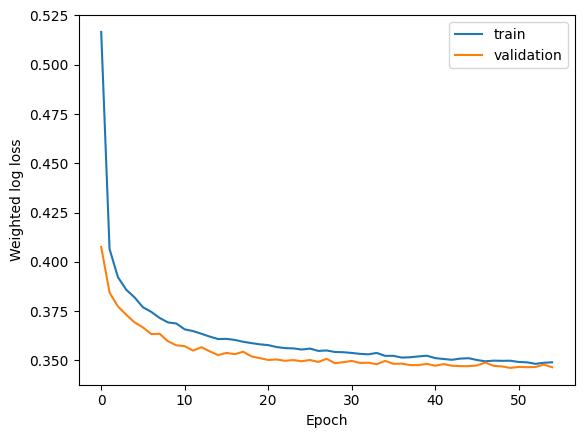

In [29]:
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Weighted log loss"); plt.legend(); plt.show()

## Evaluate on the test set and compare to XGboost


In [32]:
model.eval()
with torch.no_grad():
    logits = model(torch.tensor(X_te_s).to(device))
    score_mlp = torch.sigmoid(logits).cpu().numpy()

### Load XGboosts test scores

In [34]:
from sklearn.metrics import roc_auc_score, roc_curve
from src.metrics import background_rejection

y_te = test_df[LABEL].values
score_xgb = np.load(DATA + "preds_xgb_test_nominal.npy")

for name, s in [("XGBoost", score_xgb), ("MLP", score_mlp)]:
    print(f"{name:8s} AUC {roc_auc_score(y_te, s):.4f}  "
          f"R50 {background_rejection(y_te, s, weights=None, signal_efficiency=0.5):.1f}  "
          f"R80 {background_rejection(y_te, s, weights=None, signal_efficiency=0.8):.1f}")

XGBoost  AUC 0.9264  R50 36.3  R80 8.6
MLP      AUC 0.9288  R50 37.7  R80 9.0


### Comparison plot

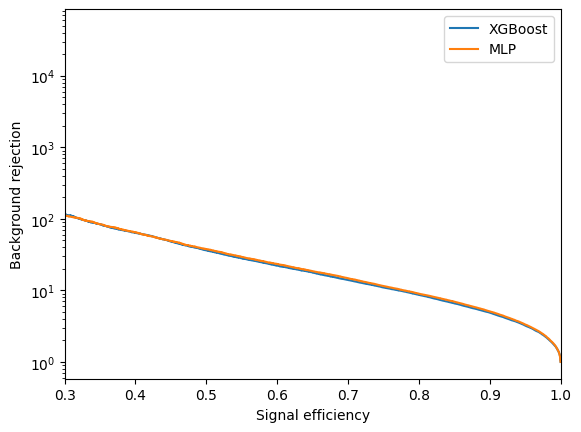

In [35]:
for name, s in [("XGBoost", score_xgb), ("MLP", score_mlp)]:
    fpr, tpr, _ = roc_curve(y_te, s)
    m = fpr > 0
    plt.plot(tpr[m], 1 / fpr[m], label=name)
plt.yscale("log"); plt.xlim(0.3, 1)
plt.xlabel("Signal efficiency"); plt.ylabel("Background rejection")
plt.legend(); plt.savefig(OUT + "roc_comparison.png", dpi=150); plt.show()

## Save everything for the robustness test

In [36]:
np.save(DATA + "preds_mlp_test_nominal.npy", score_mlp)
torch.save(model.state_dict(), DATA + "mlp_model.pt")